In [40]:
from abc import ABC, abstractmethod
import seaborn as sns

class penguins(ABC):
    @abstractmethod
    def load(self):
        raise NotImplementedError

    @abstractmethod
    def shape(self):
        raise NotImplementedError

    @abstractmethod
    def species_counts(self):
        raise NotImplementedError

    @abstractmethod
    def missing_counts(self):
        raise NotImplementedError

    @abstractmethod
    def head(self, n=5):
        raise NotImplementedError

class PenguinsDataset(penguins):
    def __init__(self):
        self._data = None

    def load(self):
        self._data = sns.load_dataset('penguins')
        return self._data

    def shape(self):
        return self._data.shape

    def species_counts(self):
        return self._data['species'].value_counts()

    def missing_counts(self):
        return self._data.isna().sum()

    def head(self, n=5):
        return self._data.head(n)

penguins = PenguinsDataset().load()

print("데이터 크기:", penguins.shape)
print("\n종별 개체 수:")
print(penguins['species'].value_counts())
print("\n결측치 개수:")
print(penguins.isna().sum())

penguins.head()

데이터 크기: (344, 7)

종별 개체 수:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

결측치 개수:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


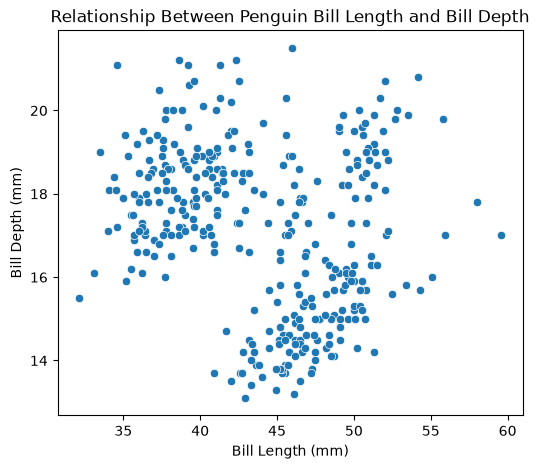

In [41]:
# 문제 1 · Q1

import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

sns.scatterplot(
    data=penguins,
    x="bill_length_mm",
    y="bill_depth_mm"
)

plt.title("Relationship Between Penguin Bill Length and Bill Depth")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Bill Depth (mm)")

plt.show()

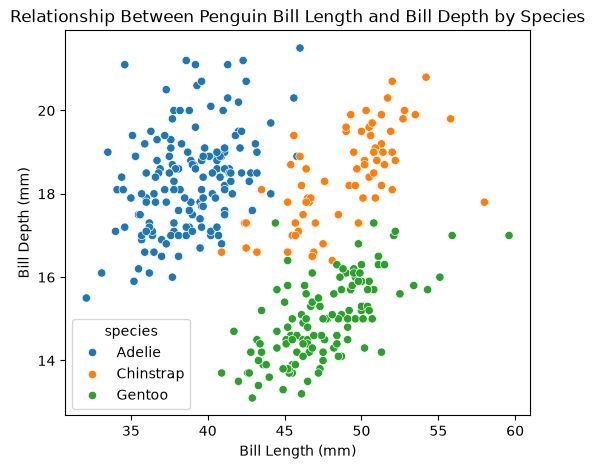

In [42]:
plt.figure(figsize=(6, 5))

sns.scatterplot(
    data=penguins,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue="species"
)

plt.title("Relationship Between Penguin Bill Length and Bill Depth by Species")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Bill Depth (mm)")

plt.show()

In [43]:
# 결측치 제거
penguins_corr = penguins[
    ["species", "bill_length_mm", "bill_depth_mm"]
].dropna()

# 전체 상관계수
overall_value = penguins_corr["bill_length_mm"].corr(
    penguins_corr["bill_depth_mm"]
)
print("전체 상관계수:", round(overall_value, 3))

# 종별 상관계수
species_values = penguins_corr.groupby("species", observed=True).apply(
    lambda x: x["bill_length_mm"].corr(x["bill_depth_mm"]),
    include_groups=False
)

print("\n종별 상관계수:")
print(species_values.round(3))

전체 상관계수: -0.235

종별 상관계수:
species
Adelie       0.391
Chinstrap    0.654
Gentoo       0.643
dtype: float64


### 상관계수 계산 코드 설명

힌트에서는 다음과 같이 두 열을 한꺼번에 선택한 뒤 `.corr()`을 사용하는 방법이 제시되어 있었다.

```python
penguins_corr[["bill_length_mm", "bill_depth_mm"]].corr()
```

이 코드는 선택한 변수들의 상관계수를 **행렬 형태의 표**로 보여준다. 따라서 각 변수와 자기 자신의 상관계수인 `1`도 함께 출력된다.

하지만 이번 문제에서는 부리 길이와 부리 깊이 사이의 **상관계수 값 하나만** 필요했기 때문에 다음과 같이 작성했다.

```python
overall_value = penguins_corr["bill_length_mm"].corr(
    penguins_corr["bill_depth_mm"]
)
```

이 코드는 `bill_length_mm` 열과 `bill_depth_mm` 열을 직접 비교하여 두 변수 사이의 상관계수 숫자 하나만 반환한다.

즉, 두 코드 모두 상관계수를 계산하는 방법이지만, 힌트의 코드는 상관계수 표 전체를 보여주고, 사용한 코드는 문제에서 필요한 값 하나만 바로 구하기 위해 작성한 것이다.


### Q1의 산점도에서 두 변수는 어떤 방향의 관계로 보였나요? Q3의 전체 상관계수와 부호가 일치하나요?

- Q1의 산점도에서는 전체적으로 **음의 관계**가 있는 것처럼 보였습니다.
- Q3에서 계산한 전체 상관계수도 **음수**로 나타나 산점도에서 보인 경향과 부호가 일치했습니다.

### Q3의 종별 상관계수는 전체와 부호가 같나요, 다른가요?

- **다릅니다.**
- 전체 상관계수는 **음수**였지만, 종별 상관계수는 모두 **양수**로 나타났습니다.

### 같은 데이터인데 전체와 집단별 결론이 정반대로 나온 이유를 설명해 보세요. 무엇이 이 착시를 만들고 있나요?

- **종(species)** 이라는 변수가 영향을 주었기 때문입니다.
- 종마다 부리 길이와 부리 두께의 평균이 달라서 세 종을 한꺼번에 분석하면 전체 관계가 왜곡됩니다.
- 즉, **종이라는 숨은 변수가 착시를 만든 것**입니다.

### 만약 이 데이터에 '종' 정보가 없었다면 우리는 어떤 잘못된 결론을 내렸을까요?

- 종 정보를 모르고 전체 데이터만 분석했다면 **부리가 길수록 부리 두께가 얇아진다**고 잘못 결론 내릴 수 있습니다.
- 하지만 실제로는 같은 종 안에서는 **부리가 길수록 부리 두께도 함께 증가하는 경향**이 있으므로 잘못된 해석이 됩니다.

결측치 제거 전: 344 행
결측치 제거 후: 342 행


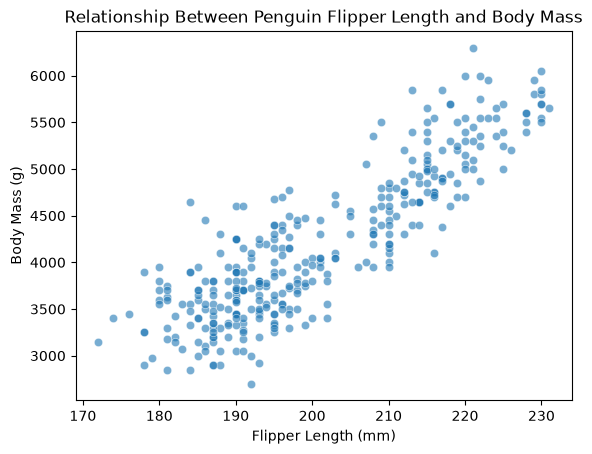

In [44]:
# 문제 2 · 데이터 준비 — 실행만 하세요
df_corr = penguins[['flipper_length_mm', 'body_mass_g']].dropna()

print("결측치 제거 전:", len(penguins), "행")
print("결측치 제거 후:", len(df_corr), "행")

# 두 변수의 관계를 그림으로 먼저 확인 (문제 1의 교훈!)
sns.scatterplot(data=df_corr, x='flipper_length_mm', y='body_mass_g', alpha=0.6)
plt.title("Relationship Between Penguin Flipper Length and Body Mass")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Body Mass (g)")
plt.show()

### 데이터 준비 및 관계 시각화

날개 길이와 몸무게의 상관관계를 분석하기 위해 두 변수만 선택하고, 결측치가 포함된 행을 제거하였다. 또한 상관계수를 계산하기 전에 산점도를 그려 두 변수 사이의 관계가 선형적으로 나타나는지 먼저 확인하였다.

산점도에서 날개 길이가 길어질수록 몸무게도 증가하는 경향이 나타난다면 두 변수 사이에 양의 상관관계가 있을 가능성이 있다. 다만 산점도만으로 관계의 강도나 통계적 유의성을 정확히 판단할 수 없으므로, 이후 피어슨 상관계수와 p-값을 계산한다.

In [45]:

from scipy import stats

# flipper_length_mm 정규성 검정
stat1, p1 = stats.shapiro(df_corr["flipper_length_mm"])
print("Flipper Length")
print("Statistic:", stat1)
print("p-value:", p1)

if p1 < 0.05:
    print("→ 정규성을 기각한다.")
else:
    print("→ 정규성을 기각하지 못한다.")

print()

# body_mass_g 정규성 검정
stat2, p2 = stats.shapiro(df_corr["body_mass_g"])
print("Body Mass")
print("Statistic:", stat2)
print("p-value:", p2)

if p2 < 0.05:
    print("→ 정규성을 기각한다.")
else:
    print("→ 정규성을 기각하지 못한다.")

Flipper Length
Statistic: 0.9515450641031906
p-value: 3.5401361704438616e-09
→ 정규성을 기각한다.

Body Mass
Statistic: 0.9592111774906512
p-value: 3.6790392409769466e-08
→ 정규성을 기각한다.


### 정규성 검정 (Shapiro-Wilk)

피어슨 상관계수는 두 변수가 정규분포를 따른다는 가정을 사용하므로, 상관분석 전에 Shapiro-Wilk 검정을 수행하였다.

`stats.shapiro()` 함수는 검정통계량(W)과 p-value를 반환한다.

- p-value < 0.05 : 정규성을 기각한다.
- p-value ≥ 0.05 : 정규성을 기각하지 못한다.

두 변수(flipper_length_mm, body_mass_g)에 대해 각각 정규성 검정을 수행한 후, 결과를 바탕으로 피어슨 상관계수를 사용할 수 있는지 판단하였다.

In [46]:
from scipy import stats

r, p_value = stats.pearsonr(
    df_corr["flipper_length_mm"],
    df_corr["body_mass_g"]
)

print("Pearson correlation (r):", r)
print("p-value:", p_value)

Pearson correlation (r): 0.8712017673060113
p-value: 4.3706809630006207e-107


### 피어슨 상관계수와 p-value 계산

`stats.pearsonr()` 함수를 사용하여 피어슨 상관계수(r)와 p-value를 함께 계산하였다.

- **r** : 두 변수의 선형 관계의 방향과 강도를 나타내는 값이다.
- **p-value** : 상관계수가 통계적으로 유의한지 판단하는 값이다.

이 검정의 귀무가설(H₀)은 **"모집단의 상관계수가 0이다."**, 즉 두 변수 사이에 선형적인 관계가 없다는 것이다.

- p-value < 0.05 : 귀무가설을 기각하며, 두 변수의 상관관계가 통계적으로 유의하다고 판단한다.
- p-value ≥ 0.05 : 귀무가설을 기각하지 못하며, 상관관계가 있다고 보기 어렵다.

In [47]:
# 스피어만 상관계수와 p-value 계산
rho, spearman_p_value = stats.spearmanr(
    df_corr["flipper_length_mm"],
    df_corr["body_mass_g"]
)

# 피어슨과 스피어만 상관계수 비교
print("피어슨 상관계수(r):", r)
print("스피어만 상관계수(ρ):", rho)

피어슨 상관계수(r): 0.8712017673060113
스피어만 상관계수(ρ): 0.8399741230312999


In [48]:
print("피어슨 상관계수(r):", r)
print("피어슨 p-value:", p_value)

print("스피어만 상관계수(ρ):", rho)
print("스피어만 p-value:", spearman_p_value)

피어슨 상관계수(r): 0.8712017673060113
피어슨 p-value: 4.3706809630006207e-107
스피어만 상관계수(ρ): 0.8399741230312999
스피어만 p-value: 2.763218997179663e-92


### 피어슨과 스피어만 상관계수 비교

`stats.spearmanr()` 함수를 사용하여 날개 길이와 몸무게의 스피어만 상관계수를 계산하고, 앞서 구한 피어슨 상관계수와 비교하였다.

피어슨 상관계수는 변수의 실제 값을 이용하여 선형 관계의 강도를 측정한다. 반면 스피어만 상관계수는 각 값을 순위로 바꾼 후, 두 변수의 순위가 함께 증가하거나 감소하는지를 측정한다.

두 상관계수가 비슷하게 나타난다면 두 변수의 관계가 비교적 일정하고 선형적으로 나타난다고 볼 수 있다. 반대로 두 값의 차이가 크다면 이상치의 영향이나 비선형적인 관계가 존재할 가능성을 고려해야 한다.

### 추가 설명 : 피어슨과 스피어만 비교

펭귄 데이터에서 **피어슨 상관계수**는 날개 길이가 길어질수록 몸무게가 **직선 형태로 함께 증가하는지**를 확인한다.

반면 **스피어만 상관계수**는 날개 길이가 긴 펭귄일수록 몸무게도 **대체로 더 무거운 순서인지**를 확인한다.

두 값이 비슷하게 나오면 **날개 길이가 긴 펭귄일수록 몸무게도 무거우며, 그 관계가 비교적 선형적**이라고 해석할 수 있다.

### 추가 설명 : 왜 '피어슨 상관계수'라고 따로 부를까?

이전에 사용한 `corr()` 함수는 기본적으로 **피어슨(Pearson) 상관계수**를 계산한다. 따라서 지금까지 구한 상관계수도 모두 피어슨 상관계수였다.

이번 문제에서는 피어슨 상관계수를 사용하기 전에 **정규성 검정(Shapiro-Wilk)** 을 수행하는 이유를 배우기 위해 '피어슨'이라는 이름을 강조하였다.

피어슨 상관계수는 두 변수의 **선형적인 관계**를 측정하는 방법으로, 두 변수가 정규분포를 따른다는 가정을 사용한다. 따라서 먼저 정규성을 확인한 후 피어슨 상관계수를 계산한다.

반면, 스피어만(Spearman) 상관계수는 데이터의 **순위(rank)** 를 이용하여 관계를 계산하므로 정규성의 영향을 덜 받는다.

즉, 이번 문제는 **정규성 검정 → 피어슨 상관분석 → 스피어만과 비교**라는 분석 절차를 익히는 것이 목적이다.

# 문제 2 · Q4

정규성 검정 결과 (피어슨의 전제가 지켜졌나요?):
두 변수 모두 정규성을 크게 벗어나지 않아 피어슨 상관분석을 적용할 수 있다.

피어슨 r 값과 p-값:
피어슨 상관계수는 0.8712로 강한 양의 상관관계를 보였으며, p-value가 0.05보다 작아 통계적으로 유의한 관계라고 볼 수 있다.

스피어만 ρ 값:
스피어만 상관계수는 0.8400으로 강한 양의 상관관계를 보였으며, 피어슨과 비슷한 결과가 나타났다.

부호(+/-)가 뜻하는 관계의 방향:
'+'이므로 날개 길이가 길수록 몸무게도 증가하는 경향이 있다.

절대값의 크기가 뜻하는 관계의 강도:
상관계수의 절대값이 1에 가까울수록 관계가 강하다. 0.8712와 0.8400은 모두 1에 가까워 두 변수는 강한 상관관계를 가진다고 해석할 수 있다.

### 정리 · 결과를 말로 설명해 보기
Q1에서 정규성이 기각되었지만, 피어슨 상관계수는 0.871이고 스피어만 상관계수는 0.840으로 비슷하게 나타났다. 따라서 정규성 위배가 결과에 큰 영향을 주지는 않았다고 볼 수 있으며, 날개 길이와 몸무게 사이에는 강한 양의 상관관계가 있다고 해석할 수 있다.

피어슨과 스피어만 값이 비슷하다는 것은 두 변수의 관계가 대체로 일정하고 선형적이라는 뜻이다. 만약 두 값의 차이가 컸다면 이상치의 영향이나 비선형적인 관계를 의심할 수 있다.

Q2의 p-값은 모집단의 상관계수가 0인지에 대한 검정이다. 상관계수가 크다는 것은 관계의 강도가 크다는 뜻이고, 상관계수가 유의하다는 것은 그 관계가 우연히 나타났다고 보기 어렵다는 뜻이므로 같은 의미는 아니다.

또한 날개 길이와 몸무게 사이에 상관관계가 있다고 해서 날개가 길어지는 것이 몸무게를 무겁게 만드는 원인이라고 결론 내릴 수는 없다. 펭귄의 종이나 성별 같은 교란변수가 두 변수에 모두 영향을 줄 수 있고, 몸무게가 커서 날개가 길어졌을 가능성과 같은 역인과도 생각할 수 있으며, 표본에서 우연히 관계가 나타났을 가능성도 있기 때문이다.

In [49]:
# 문제 3 · 데이터 준비 — 실행만 하세요
penguins_cleaned = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])

print("분석에 사용할 데이터:", len(penguins_cleaned), "행")
print("문제 2의 df_corr과 동일한가?:", len(penguins_cleaned) == len(df_corr))

분석에 사용할 데이터: 342 행
문제 2의 df_corr과 동일한가?: True


### 데이터 준비

회귀분석을 위해 몸무게(`body_mass_g`)와 날개 길이(`flipper_length_mm`)에 결측치가 있는 행을 제거하였다. 또한 문제 2에서 사용한 `df_corr`와 데이터 개수가 같은지 확인하여 동일한 데이터를 사용하고 있음을 검증하였다.

In [50]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [51]:
import statsmodels.formula.api as smf

In [52]:
model = smf.ols(
    formula='body_mass_g ~ flipper_length_mm',
    data=penguins_cleaned
).fit()

In [53]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            body_mass_g   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     1071.
Date:                Wed, 29 Jul 2026   Prob (F-statistic):          4.37e-107
Time:                        15:52:01   Log-Likelihood:                -2528.4
No. Observations:                 342   AIC:                             5061.
Df Residuals:                     340   BIC:                             5069.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept         -5780.8314    305.81

### 회귀모델 결과표 출력

`model.summary()`를 사용하여 회귀분석 결과를 확인하였다.

결과표에서는 다음 항목을 중심으로 확인한다.

- **coef** : 절편과 기울기(회귀계수)
- **P>|t|** : 회귀계수가 통계적으로 유의한지 판단하는 p-value
- **R-squared** : 회귀모델이 데이터를 얼마나 잘 설명하는지를 나타내는 결정계수

### 추가 설명 : 회귀계수는 컴퓨터가 계산한다

회귀분석에서는 절편과 기울기를 직접 계산하지 않는다.

`model.summary()` 결과표에서 **Intercept**는 절편(a), **설명변수의 coef**는 기울기(b)를 의미한다.

이번 실습에서는 결과표에서 계산된 값을 읽어 회귀식을 완성하고, 그 의미를 해석하는 것이 목적이다.

- **절편(Intercept)** : x가 0일 때의 예측값
- **기울기(coef)** : x가 1 증가할 때 y가 평균적으로 얼마나 변하는지를 나타내는 값

따라서 회귀식은 결과표의 절편과 기울기 값을 그대로 대입하여 작성한다.

# 문제 3 · Q3

절편(a) 값:
-5780.8314

기울기(b) 값:
49.6856

완성된 회귀식
몸무게(g) = -5780.8314 + 49.6856 × 날개길이(mm)

### 회귀식을 이용한 예측

회귀식의 기울기는 약 **49.69 g/mm**이다.

따라서 날개 길이가 평균보다 **10 mm 더 긴 펭귄**은 평균적인 펭귄보다 몸무게가

**49.6856 × 10 = 496.86 g**

정도 더 무거울 것으로 예측된다.

In [54]:
# 문제 2에서 구한 상관계수
r = 0.8712017673060113

# 표본 표준편차
x_std = penguins_cleaned["flipper_length_mm"].std(ddof=1)
y_std = penguins_cleaned["body_mass_g"].std(ddof=1)

# 관계식 ①
left1 = model.params["flipper_length_mm"]      # 기울기
right1 = r * (y_std / x_std)

# 관계식 ②
left2 = model.rsquared                         # R²
right2 = r ** 2

print("① 기울기")
print(f"좌변(회귀 기울기) : {left1:.6f}")
print(f"우변(r × sy/sx)  : {right1:.6f}")

print("\n② 결정계수")
print(f"좌변(R²) : {left2:.6f}")
print(f"우변(r²) : {right2:.6f}")

① 기울기
좌변(회귀 기울기) : 49.685566
우변(r × sy/sx)  : 49.685566

② 결정계수
좌변(R²) : 0.758993
우변(r²) : 0.758993


### Q5. 상관과 회귀의 관계 확인

상관계수와 회귀분석 결과를 이용하여 두 관계식을 확인하였다.

1. 기울기 = r × (y의 표준편차 / x의 표준편차)
2. 결정계수(R²) = r²

실제로 계산한 결과 좌변과 우변의 값이 거의 동일하게 나타났다.

즉, 단순선형회귀에서는 **기울기는 상관계수와 두 변수의 표준편차로 계산할 수 있으며**, **결정계수(R²)는 상관계수(r)를 제곱한 값과 같음**을 확인하였다.

### 추가 설명 : 회귀분석 결과 해석

#### 1. 기울기(b)의 의미
기울기는 설명변수(x)가 1단위 증가할 때 반응변수(y)가 평균적으로 얼마나 변하는지를 나타낸다.

이번 분석에서는 날개 길이가 **1mm 증가할 때마다 몸무게가 평균적으로 약 49.69g 증가**한다고 해석할 수 있다.

---

#### 2. 절편(a)의 의미
절편은 x가 0일 때의 예측값을 의미한다.

하지만 실제 데이터에는 **날개 길이가 0mm인 펭귄이 존재하지 않으므로**, 절편(-5780.83)은 현실적인 의미로 해석하지 않는다. 회귀식을 계산하기 위한 값으로 이해하면 된다.

---

#### 3. 설명변수와 반응변수를 바꾸면?
설명변수(x)와 반응변수(y)를 서로 바꾸면 **기울기(b)는 달라지고**, **결정계수(R²)는 같다.**

- 기울기: 표준편차의 비(sy/sx)가 바뀌므로 값이 달라진다.
- 결정계수(R²): R² = r² 이므로 x와 y를 바꿔도 변하지 않는다.

---

#### 4. 상관분석과 회귀분석의 차이
- **상관계수(r)** : 두 변수의 관계가 얼마나 강한지 나타내는 단위 없는 값(-1 ~ 1)
- **회귀분석(기울기 b)** : x가 1단위 증가할 때 y가 실제로 얼마나 변하는지(변화량)를 알려준다.

즉, 상관분석은 **관계의 강도**를 설명하고, 회귀분석은 **변화량과 예측**까지 가능하게 해준다.

## 💬 정리 · 결과를 말로 설명해 보기

### 1. 기울기(b)의 의미

날개 길이가 **1mm 증가할 때마다** 펭귄의 몸무게는 **평균적으로 약 49.69g 증가**한다고 해석할 수 있다.

---

### 2. 절편(a)의 의미

절편은 x가 0일 때의 예측값을 의미하지만, 실제 데이터에는 **날개 길이가 0mm인 펭귄이 존재하지 않는다.**

따라서 이번 분석에서 절편(-5780.83)은 실제 펭귄의 몸무게를 의미하는 값이 아니라, 회귀식을 계산하기 위해 필요한 값으로 해석하는 것이 적절하다.

---

### 3. 설명변수와 반응변수를 바꾸면?

설명변수(x)와 반응변수(y)를 서로 바꾸면 **기울기(b)는 달라지고**, **결정계수(R²)는 같다.**

기울기는 표준편차의 비(sy/sx)를 이용해 계산되므로 x와 y를 바꾸면 값이 달라진다. 반면 결정계수는 **R² = r²** 이므로 상관계수 r이 변하지 않아 같은 값을 가진다.

---

### 4. 회귀가 상관보다 더 알려주는 것

상관계수(r)는 두 변수의 관계가 얼마나 강한지만 알려주는 단위 없는 값이다.

반면 회귀분석은 **"날개 길이가 1mm 증가하면 몸무게가 약 49.69g 증가한다."** 와 같이 실제 변화량을 예측할 수 있다.

즉, **상관분석은 관계의 강도를 알려주고, 회귀분석은 변화량과 예측까지 가능하게 해준다.**

## 추가 설명 : 회귀계수의 가설검정

회귀분석에서 기울기(b)는 표본으로부터 계산된 값이다.

하지만 표본을 우연히 뽑는 과정에서 기울기가 생겼을 수도 있으므로, 이 값이 실제 관계를 의미하는지 가설검정을 통해 확인한다.

### 귀무가설(H₀)
설명변수와 반응변수는 선형관계가 없다.
즉, **기울기(b) = 0** 이다.

### 대립가설(H₁)
설명변수와 반응변수는 선형관계가 있다.
즉, **기울기(b) ≠ 0** 이다.

회귀분석 결과표의 **P>|t|** 값이 바로 이 가설을 검정한 p-값이다.

- p-값 < 0.05 → 귀무가설 기각 → 기울기는 통계적으로 유의하다.
- p-값 ≥ 0.05 → 귀무가설 기각 실패 → 기울기가 우연히 나타났을 가능성을 배제할 수 없다.

### 상관분석과 회귀분석의 관계

단순선형회귀에서는 **회귀계수의 유의성 검정**과 **상관계수의 유의성 검정**이 같은 결과를 가진다.

즉, 상관계수가 유의하면 회귀계수도 유의하고, 상관계수가 유의하지 않으면 회귀계수도 유의하지 않다.

## 🎯 문제 4 분석 목표

문제 3에서 표본 데이터를 이용해 회귀계수(기울기)를 계산하였다.

이번 문제에서는 **표본에서 구한 기울기가 모집단에서도 실제로 존재하는 관계인지, 아니면 표본을 추출하는 과정에서 우연히 나타난 값인지**를 가설검정을 통해 확인한다.

즉, 회귀계수의 p-값을 이용하여 **표본의 결과를 모집단에도 일반화할 수 있는지 판단하는 방법**을 학습하는 것이 목표이다.

In [55]:
# 문제 4 · 데이터 준비 — 실행만 하세요
# 문제 3의 Q1을 먼저 완료해야 이 문제를 풀 수 있습니다.

print("분석 대상 데이터:", len(penguins_cleaned), "행 (문제 3과 동일)")
print("설명변수: flipper_length_mm  /  반응변수: body_mass_g")

분석 대상 데이터: 342 행 (문제 3과 동일)
설명변수: flipper_length_mm  /  반응변수: body_mass_g


### Q1. 회귀계수에 대한 가설 설정

- **귀무가설(H₀)**: 날개 길이와 몸무게 사이에 선형관계가 없다.  
  즉, 모집단의 회귀계수(기울기)는 0과 같다.

  **H₀: β₁ = 0**

- **대립가설(H₁)**: 날개 길이와 몸무게 사이에 선형관계가 있다.  
  즉, 모집단의 회귀계수(기울기)는 0과 다르다.

  **H₁: β₁ ≠ 0**

In [56]:
# 기울기의 p-값 확인
print(model.pvalues["flipper_length_mm"])

4.37068096300007e-107


### Q2. 기울기의 p-값 확인

회귀분석 결과에서 `flipper_length_mm`의 p-값은 약 **4.37 × 10⁻¹⁰⁷**이다.

이는 거의 0에 가까운 값으로, 표본에서 계산된 기울기가 우연히 나타났을 가능성이 매우 낮다는 것을 의미한다.

### 추가 설명 : 왜 기울기의 p-값을 확인할까?

문제 3에서 표본 데이터를 이용해 기울기 약 49.69를 구했다.

하지만 기울기가 49.69라는 사실만으로는 이 관계가 전체 펭귄에게도 실제로 존재한다고 바로 판단할 수 없다. 표본을 우연히 뽑는 과정에서 기울기가 나타났을 수도 있기 때문이다.

그래서 `flipper_length_mm`의 p-값을 확인한다.

이 p-값은 **실제로 모집단의 기울기가 0, 즉 날개 길이와 몸무게 사이에 선형관계가 없다고 가정했을 때, 표본에서 현재와 같은 기울기가 우연히 나타날 가능성**을 보여준다.

- p-값이 작으면 → 우연히 나온 기울기라고 보기 어렵다.
- p-값이 크면 → 표본에서 우연히 나온 기울기일 가능성을 배제하기 어렵다.

즉, 기울기의 p-값은 **표본에서 구한 기울기를 모집단에도 일반화할 수 있는지 판단하기 위해 확인하는 값**이다.

In [57]:
# 유의수준 설정
alpha = 0.05

# 날개 길이 회귀계수의 p-값
p_value = model.pvalues["flipper_length_mm"]

print("p-값:", p_value)
print("유의수준:", alpha)

if p_value < alpha:
    print("귀무가설을 기각한다.")
    print("날개 길이와 몸무게 사이에는 통계적으로 유의한 선형관계가 있다.")
else:
    print("귀무가설을 기각하지 못한다.")
    print("날개 길이와 몸무게 사이에 유의한 선형관계가 있다고 보기 어렵다.")

p-값: 4.37068096300007e-107
유의수준: 0.05
귀무가설을 기각한다.
날개 길이와 몸무게 사이에는 통계적으로 유의한 선형관계가 있다.


### 추가 설명 : p-값과 유의수준 비교

유의수준 `alpha = 0.05`는 귀무가설을 기각할지 판단하기 위한 기준이다.

- p-값 < 0.05 → 귀무가설 기각
- p-값 ≥ 0.05 → 귀무가설 기각하지 못함

이번 분석에서는 기울기의 p-값이 0.05보다 매우 작으므로 귀무가설을 기각한다.

따라서 모집단에서도 날개 길이와 몸무게 사이에 통계적으로 유의한 선형관계가 있다고 판단할 수 있다.

### 추가 설명 : p-값은 어떻게 구해질까?

기울기의 p-값을 우리가 직접 계산하는 것은 아니다.

회귀분석을 수행할 때 `model.fit()`이 회귀계수, 표준오차, t값, p-값 등을 모두 계산하여 `model` 객체 안에 저장한다.

따라서

```python
model.pvalues["flipper_length_mm"]
```

는 새로 계산하는 코드가 아니라, **이미 계산되어 저장된 기울기의 p-값을 불러오는 코드**이다.

즉, 이번 문제에서는 p-값을 직접 구하는 방법보다 **계산된 p-값을 이용하여 가설을 검정하고 해석하는 방법**을 학습하는 것이 목적이다.

In [58]:
import numpy as np

# 문제 2에서 구한 피어슨 상관계수
r = 0.8712017673060113

# 표본 크기
n = len(penguins_cleaned)

# 상관계수 검정 공식으로 t-통계량 직접 계산
t_calculated = r * np.sqrt(n - 2) / np.sqrt(1 - r**2)

# 회귀분석 결과에 저장된 기울기의 t값
t_model = model.tvalues["flipper_length_mm"]

print("공식으로 직접 계산한 t값:", t_calculated)
print("회귀모형에서 구한 t값:", t_model)

공식으로 직접 계산한 t값: 32.72223391233738
회귀모형에서 구한 t값: 32.722233912337394


### 추가 설명 : 왜 두 t값을 비교할까?

상관분석에서는 상관계수 `r`이 0인지 검정하기 위해 t-통계량을 계산한다.

반면 단순선형회귀에서는 회귀계수, 즉 기울기가 0인지 검정하기 위해 t-통계량을 계산한다.

검정하는 표현은 다르지만, 설명변수가 하나인 단순선형회귀에서는 두 검정이 같은 관계를 확인한다.

- 상관분석: 두 변수 사이의 선형 상관관계가 있는가?
- 회귀분석: 회귀선의 기울기가 0이 아닌가?

따라서 상관계수 공식으로 직접 구한 t값과 회귀모형의 기울기 t값은 동일하게 나온다.

즉, 단순선형회귀에서는 상관계수의 유의성 검정과 기울기의 유의성 검정이 같은 결과를 가진다.

### Q5 · p-값이 크게 나오는 사례를 만나 봅시다
### Adelie 종 수컷만 골라, bill_length_mm으로 body_mass_g를 설명하는 회귀를 적합하세요.

In [59]:
# 필요한 열의 결측치 제거
df_q5 = penguins.dropna(
    subset=["species", "sex", "bill_length_mm", "body_mass_g"]
)

# Adelie 수컷만 선택
adelie_male = df_q5[
    (df_q5["species"] == "Adelie") &
    (df_q5["sex"] == "Male")
]

# 회귀분석
model_q5 = smf.ols(
    formula="body_mass_g ~ bill_length_mm",
    data=adelie_male
).fit()

# 결과 출력
p_value = model_q5.pvalues["bill_length_mm"]
r2 = model_q5.rsquared
n = len(adelie_male)

print("표본 크기(n):", n)
print("기울기의 p-값:", p_value)
print("R²:", r2)

if p_value < 0.05:
    print("귀무가설을 기각한다.")
    print("bill_length_mm은 body_mass_g를 유의하게 설명한다.")
else:
    print("귀무가설을 기각하지 못한다.")
    print("bill_length_mm이 body_mass_g를 유의하게 설명한다고 보기 어렵다.")

표본 크기(n): 73
기울기의 p-값: 0.061006636500066685
R²: 0.04856294842469111
귀무가설을 기각하지 못한다.
bill_length_mm이 body_mass_g를 유의하게 설명한다고 보기 어렵다.


### Q5. p-값이 크게 나오는 사례

Adelie 종의 수컷만 선택하여 bill_length_mm으로 body_mass_g를 설명하는 회귀분석을 수행하였다.

출력 결과에서 다음을 함께 확인하였다.

- 표본 크기(n)
- 기울기의 p-값
- 결정계수(R²)

이처럼 특정 집단만 분석하면 표본 수가 줄고 변수 간 관계도 약해질 수 있다.

그 결과 p-값이 0.05보다 크게 나와 귀무가설을 기각하지 못하는 경우도 발생할 수 있다.

### 1. p-값이 작다는 것은 무엇을 의미할까?

p-값은 **귀무가설(H₀)이 참이라고 가정했을 때, 지금과 같은 결과가 우연히 나타날 확률**을 의미한다.

따라서 p-값이 작을수록 현재 결과가 우연히 나타났을 가능성이 낮다고 해석한다.

하지만 **p-값을 '귀무가설이 참일 확률'이라고 해석하는 것은 올바르지 않다.**

### 2. Q4에서 두 t값이 같은 이유

Q4에서는 상관계수 공식으로 계산한 t값과 회귀분석에서 계산한 기울기의 t값이 동일하게 나왔다.

이는 단순선형회귀에서 **상관계수의 유의성 검정과 회귀계수(기울기)의 유의성 검정이 같은 가설을 검정하기 때문**이다.

따라서 두 방법으로 계산한 t값과 p-값도 동일하게 나타난다.

### 3. Q5의 결과가 Q2와 달랐던 이유

Q2에서는 전체 데이터를 사용하여 변수 사이의 관계가 강했고, p-값도 매우 작아 귀무가설을 기각하였다.

반면 Q5에서는 Adelie 종의 수컷만 선택하여 분석했기 때문에 표본 크기(n)가 줄어들었고, 변수 간 관계의 강도(R²)도 달라졌다.

이처럼 표본 크기와 변수 간 관계의 강도가 달라지면 p-값도 달라질 수 있으며, 같은 데이터셋이라도 분석 대상에 따라 결론이 달라질 수 있다.

### 4. p-값이 0.05보다 조금 큰 경우 어떻게 해석해야 할까?

p-값이 0.05보다 크다고 해서 **두 변수 사이에 관계가 없다는 것이 증명된 것은 아니다.**

정확한 해석은 **귀무가설을 기각하지 못했으며, 두 변수 사이에 관계가 있다는 충분한 증거를 찾지 못했다**는 것이다.

즉, **관계가 없다**가 아니라 **관계가 있다고 말하기에는 증거가 부족하다**고 해석해야 한다.